In [54]:
from unittest.mock import inplace

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path

import spacy


# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [4]:
df=pd.read_csv(Path.cwd().parent/'data'/"Tweets.csv")

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created                 14640 non-null  str    
 13  tweet_locati

In [7]:
df=df.sample(n=5000,random_state=42)

In [8]:
df

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
4794,569731104070115329,positive,1.0000,NaN,NaN,Southwest,NaN,JasmineDT,NaN,1,@SouthwestAir you're my early frontrunner for ...,NaN,2015-02-22 21:30:54 -0800,Washington D.C.,Eastern Time (US & Canada)
10480,569263373092823040,negative,1.0000,Cancelled Flight,1.0000,US Airways,NaN,ElizabethFrayer,NaN,0,@USAirways how is it that my flt to EWR was Ca...,NaN,2015-02-21 14:32:19 -0800,NaN,NaN
8067,568818669024907264,negative,1.0000,Late Flight,0.6770,Delta,NaN,The_Radifier,NaN,0,@JetBlue what is going on with your BDL to DCA...,NaN,2015-02-20 09:05:13 -0800,"Arlington, VA",Atlantic Time (Canada)
8880,567775864679456768,neutral,1.0000,NaN,NaN,Delta,NaN,rnlewisjr,NaN,0,@JetBlue do they have to depart from Washingto...,NaN,2015-02-17 12:01:29 -0800,"iPhone: 60.495510,-151.064590",Alaska
8292,568526521910079488,negative,0.6625,Customer Service Issue,0.3394,Delta,NaN,beantoon,NaN,0,@JetBlue I can probably find some of them. Are...,NaN,2015-02-19 13:44:20 -0800,"Plymouth, MA",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1360,569769624780165120,negative,0.7158,Lost Luggage,0.3579,United,NaN,wsachs,NaN,0,@united on plane to Newark now. I was checked ...,NaN,2015-02-23 00:03:59 -0800,New York/New Jersey depends on,Eastern Time (US & Canada)
3196,568604039430033408,neutral,0.6831,NaN,NaN,United,NaN,TheLunchBelle,NaN,0,@united @HiltonWorldwide @Caravannyc @Maysvill...,"[34.06143413, -118.39787418]",2015-02-19 18:52:21 -0800,LA / NYC,Eastern Time (US & Canada)
2037,569448465991737345,negative,1.0000,Flight Attendant Complaints,0.3440,United,NaN,MMMarketing2014,NaN,0,@united no my concerns were not addressed,NaN,2015-02-22 02:47:48 -0800,#Westford #marketing,NaN
486,567772685472915456,negative,0.6579,Customer Service Issue,0.6579,Virgin America,NaN,cayocrazy,NaN,0,@VirginAmerica Umm so no reason as to why this...,NaN,2015-02-17 11:48:51 -0800,NaN,NaN


In [10]:
df.isna().sum()

tweet_id                           0
airline_sentiment                  0
airline_sentiment_confidence       0
negativereason                  1816
negativereason_confidence       1378
airline                            0
airline_sentiment_gold          4984
name                               0
negativereason_gold             4987
retweet_count                      0
text                               0
tweet_coord                     4635
tweet_created                      0
tweet_location                  1631
user_timezone                   1706
dtype: int64

In [12]:
df.drop(columns=['tweet_id','negativereason_gold','airline_sentiment_gold','negativereason_confidence','negativereason'],inplace=True) # izbacujemo zbog previse Nan vrednosti i zbog id jer je nepotreban

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 4794 to 9701
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   airline_sentiment             5000 non-null   str    
 1   airline_sentiment_confidence  5000 non-null   float64
 2   airline                       5000 non-null   str    
 3   name                          5000 non-null   str    
 4   retweet_count                 5000 non-null   int64  
 5   text                          5000 non-null   str    
 6   tweet_coord                   365 non-null    str    
 7   tweet_created                 5000 non-null   str    
 8   tweet_location                3369 non-null   str    
 9   user_timezone                 3294 non-null   str    
dtypes: float64(1), int64(1), str(8)
memory usage: 429.7 KB


In [16]:
df.drop(columns=['tweet_coord','tweet_location','user_timezone'],inplace=True) # izbacujemo ove kolone zbog previse na vrednosti

In [20]:
df.airline_sentiment.value_counts()

airline_sentiment
negative    3184
neutral     1022
positive     794
Name: count, dtype: int64

In [21]:
#vidimo da imamo nebalansiran dataset imamo previse negativnih vrednosti i mozemo da pretpostavimo da ce model dobro pogadjiti negativni sentiment ali lose sve ostale ...
def sentiment_to_srpski(sentiment):
    if sentiment=='negative':
        return "negativan"
    if sentiment=='neutral':
        return 'neutralan'
    return 'pozitivan'


In [23]:
df.airline_sentiment=df.airline_sentiment.apply(sentiment_to_srpski)

In [26]:
df.airline_sentiment.value_counts()

airline_sentiment
negativan    3184
neutralan    1022
pozitivan     794
Name: count, dtype: int64

In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 4794 to 9701
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   airline_sentiment             5000 non-null   str    
 1   airline_sentiment_confidence  5000 non-null   float64
 2   airline                       5000 non-null   str    
 3   name                          5000 non-null   str    
 4   retweet_count                 5000 non-null   int64  
 5   text                          5000 non-null   str    
 6   tweet_created                 5000 non-null   str    
dtypes: float64(1), int64(1), str(5)
memory usage: 312.5 KB


In [29]:
df.airline.value_counts()

airline
United            1320
US Airways         998
American           911
Southwest          813
Delta              778
Virgin America     180
Name: count, dtype: int64

In [32]:
df.drop(columns='name',inplace=True) # dropujemo ime korisnika nebitno je

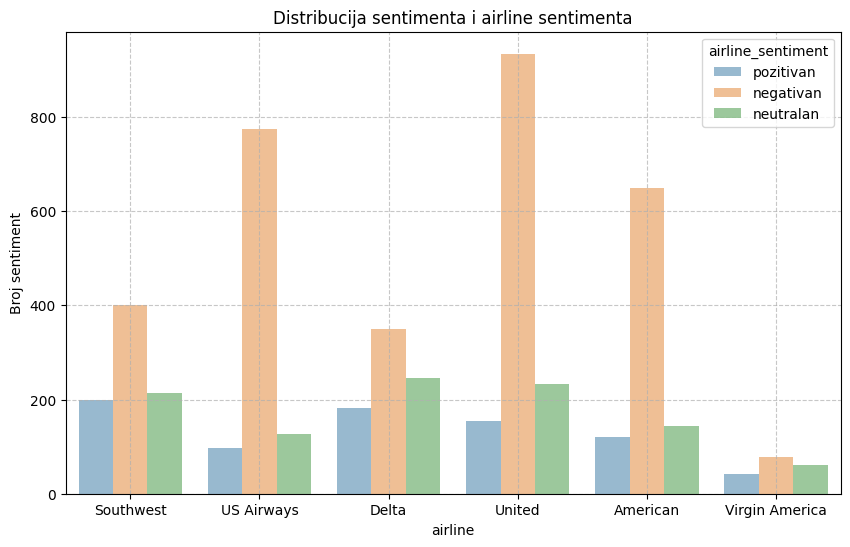

In [35]:
#proveramo bitnost kategorijske promenjive airline ..
plt.figure(figsize=(10, 6))

sb.countplot(data=df,
           x='airline',
           hue='airline_sentiment',
           fill=True,
           alpha=0.5)

plt.title('Distribucija sentimenta i airline sentimenta')
plt.xlabel('airline')
plt.ylabel('Broj sentiment')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
#vidimo da su raspodele drugacije samim tim ima smisla ukljuciti ovo u model

In [36]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 4794 to 9701
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   airline_sentiment             5000 non-null   str    
 1   airline_sentiment_confidence  5000 non-null   float64
 2   airline                       5000 non-null   str    
 3   retweet_count                 5000 non-null   int64  
 4   text                          5000 non-null   str    
 5   tweet_created                 5000 non-null   str    
dtypes: float64(1), int64(1), str(4)
memory usage: 273.4 KB


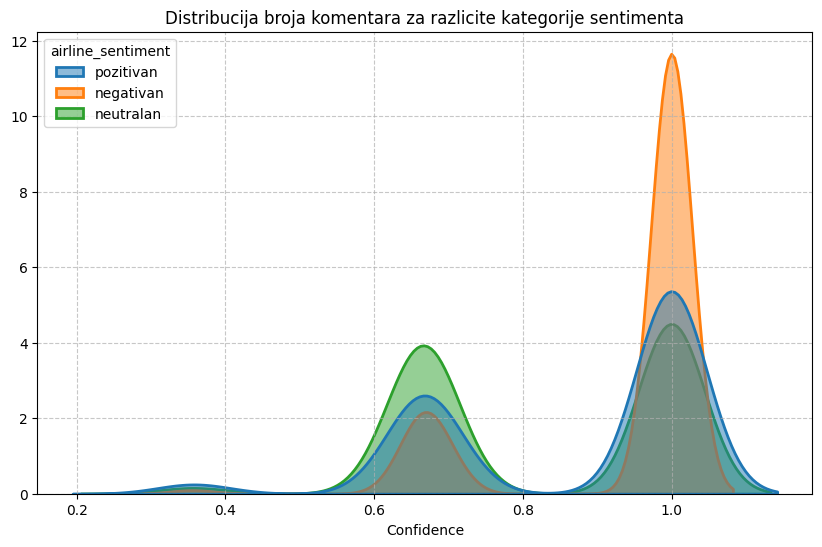

In [44]:
plt.figure(figsize=(10, 6))

sb.kdeplot(data=df,
           x='airline_sentiment_confidence',
           hue='airline_sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja komentara za razlicite kategorije sentimenta')
plt.xlabel('Confidence')
plt.ylabel('')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

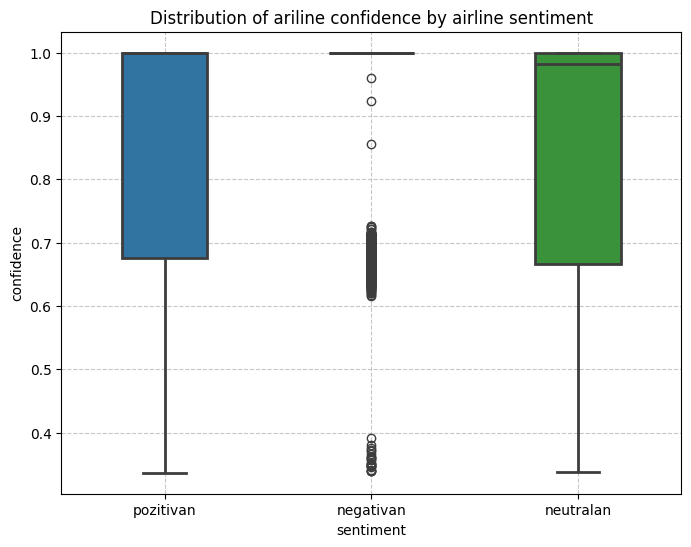

In [43]:
plt.figure(figsize=(8, 6))

sb.boxplot(data=df, x='airline_sentiment', y='airline_sentiment_confidence', hue='airline_sentiment', fill=True, saturation=0.75, width=0.55, gap=0.25, linewidth=2, legend=False)

plt.title('Distribution of ariline confidence by airline sentiment')
plt.ylabel('confidence')
plt.xlabel('sentiment')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# vidimo da imamo outliere i da generalno raspodele nisu iste samimim tim koriscemo ovo ..
# ali za ovu ce nam trebati robust scaler...

In [45]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 4794 to 9701
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   airline_sentiment             5000 non-null   str    
 1   airline_sentiment_confidence  5000 non-null   float64
 2   airline                       5000 non-null   str    
 3   retweet_count                 5000 non-null   int64  
 4   text                          5000 non-null   str    
 5   tweet_created                 5000 non-null   str    
dtypes: float64(1), int64(1), str(4)
memory usage: 273.4 KB


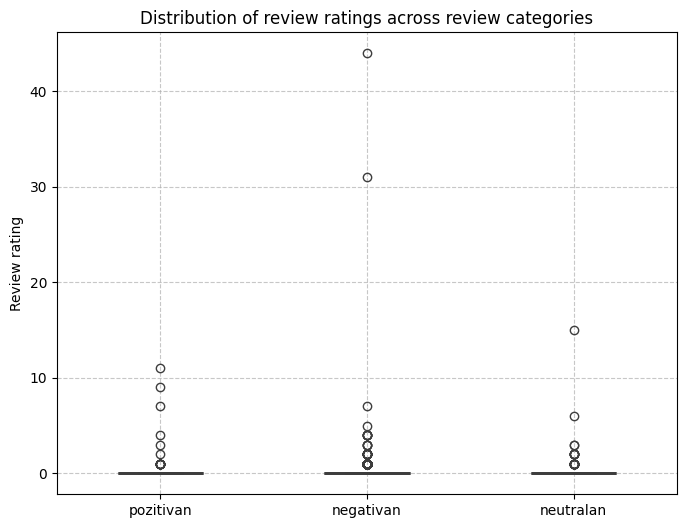

In [47]:
plt.figure(figsize=(8, 6))

sb.boxplot(data=df, x='airline_sentiment', y='retweet_count', hue='airline_sentiment', fill=True, saturation=0.75, width=0.55, gap=0.25, linewidth=2, legend=False)

plt.title('Distribution of review ratings across review categories')
plt.ylabel('Review rating')
plt.xlabel('')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [49]:
df.drop(columns='tweet_created',inplace=True)

In [50]:

df.drop(columns='retweet_count',inplace=True)

In [52]:

df.drop(columns='airline_sentiment_confidence',inplace=True)

In [ ]:
#izbacili smo datum jer je previse specifican previse unique, i ne moze da se onecode encouduje dan , onda retweet count ima istu medijuamnu , a airline sentiment confidence bi bio data leakege ...

In [53]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 4794 to 9701
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   airline_sentiment  5000 non-null   str  
 1   airline            5000 non-null   str  
 2   text               5000 non-null   str  
dtypes: str(3)
memory usage: 156.2 KB


In [56]:
one_hot_encoder=OneHotEncoder(handle_unknown='ignore')

In [58]:
nlp_pipe=spacy.load('en_core_web_md')

In [59]:
proba=nlp_pipe('ja sam vukasin')

In [60]:
proba[0]

ja

In [62]:
#fja spacy sredi tekst
def spacy_sredi_tekst(doc):
    ocisceni_tekst=[]
    tokens=nlp_pipe(doc)

    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if token.is_punct or token.like_num or token.like_url:
            continue
        if token.is_stop and lemma_lower!='not':
            continue
        if token.is_stop and lemma_lower!='no':
            continue
        ocisceni_tekst.append(lemma_lower)
    return ocisceni_tekst

In [63]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 4794 to 9701
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   airline_sentiment  5000 non-null   str  
 1   airline            5000 non-null   str  
 2   text               5000 non-null   str  
dtypes: str(3)
memory usage: 156.2 KB


In [67]:
X=df[['text','airline']]

In [68]:
y=df.airline_sentiment

In [69]:
y_encodings,y_levels=pd.factorize(y)

In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y_encodings, test_size=0.2, random_state=42,stratify=y_encodings)